# Notebook 1 — Akurasi, Gap Gender, Token & Signifikansi (MULTI-MODEL)
## Gender Persona × GSM8K

**Peneliti:** Abel Apriliani (18222008) — Tugas Akhir S1 Informatika ITB

Notebook ini membandingkan **beberapa model sekaligus** pada benchmark GSM8K lintas
persona gender, meniru gaya analisis pada `GSM8K_persona_man_&_woman.ipynb`:
pivot **model × persona**, grouped bar chart akurasi, serta analisis **gap**
(Delta implicit−explicit, Gender Gap man−woman, Deviation vs Neutral) dan dumbbell plot.

**Sumber data:** rekap agregat `TUGAS AKHIR - Gender Persona GSM8K (2).csv`
(satu baris per persona per model). Karena agregat (bukan per soal), uji signifikansi
dibatasi pada uji berbasis **hitungan benar/salah** (chi-square, two-proportion z-test,
Cohen's h). Uji berpasangan/regresi/distribusi token butuh data per-soal — lihat Bagian 7.

## Bagian 1 — Setup & Pemuatan Semua Model

In [1]:
# ── 1.1 Imports ──────────────────────────────────────────────────────────────
import csv
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, norm, fisher_exact

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
print("Library siap.")

Library siap.


In [2]:
# ── 1.2 Konfigurasi + parser CSV multi-blok ──────────────────────────────────
SOURCE_FILE = Path(r"D:\TugasAkhir\src\notebook\GSM8K\TUGAS AKHIR  - Gender Persona GSM8K (2).csv")

# 6 model fokus Tugas Akhir: label tampilan -> nilai kolom model_name di CSV
FOCUS_MODELS = {
    "DeepSeek R1 Distill Qwen-32B": "deepseek-r1-distill-qwen-32b",
    "Qwen3-Think 80B":              "Qwen3 Next 80B A3B Thinking",
    "LLaMA 3.3 70B":                "Meta Llama 3.3 70B Instruct",
    "GPT-OSS 20B":                  "OpenAI GPT-OSS-20B",
    "LLaMA 3.1 8B":                 "Meta Llama 3.1 8B Instruct",
    "Ministral 8B":                 "Mistral Ministral 8B",
}

PERSONA_ORDER = [
    "man_explicit_1", "man_implicit_1", "man_implicit_2", "man_implicit_3",
    "woman_explicit_1", "woman_implicit_1", "woman_implicit_2", "woman_implicit_3",
    "neutral",
]
PERSONA_SET = set(PERSONA_ORDER)
CORE_COLS = [
    "correct", "total", "accuracy",
    "sum_prompt_tokens", "sum_completion_tokens", "sum_reasoning_tokens", "sum_total_tokens",
    "avg_prompt_tokens", "avg_completion_tokens", "avg_reasoning_tokens", "avg_total_tokens",
]

def parse_blocks(path):
    '''CSV multi-blok: tiap model punya baris judul, baris header model_name..., lalu
    baris data per persona, ditutup baris total ALL/OVERALL. Kolom tengah tidak
    konsisten antar blok, jadi kolom diambil BERDASARKAN NAMA, hanya kolom inti disimpan.'''
    with open(path, encoding="utf-8") as f:
        rows = list(csv.reader(f))
    records, i = [], 0
    while i < len(rows):
        first = rows[i][0].strip() if rows[i] else ""
        if first == "model_name":
            header = [c.strip() for c in rows[i]]
            col_idx = {}
            for j, name in enumerate(header):
                if name and name not in col_idx:
                    col_idx[name] = j
            j = i + 1
            while j < len(rows):
                row = rows[j]
                c0 = row[0].strip() if len(row) > 0 else ""
                c1 = row[1].strip() if len(row) > 1 else ""
                if c0 == "model_name":
                    break
                if c1 in ("ALL", "OVERALL"):
                    j += 1; continue
                if c1 in PERSONA_SET:
                    def get(name):
                        idx = col_idx.get(name)
                        return row[idx].strip() if (idx is not None and idx < len(row)) else ""
                    rec = {"model": get("model_name") or c0, "persona_folder": c1}
                    for k in CORE_COLS:
                        rec[k] = get(k)
                    records.append(rec)
                j += 1
            i = j
        else:
            i += 1
    df = pd.DataFrame(records)
    for col in CORE_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

OUTPUT_DIR = Path("outputs_notebook1")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Sumber:", SOURCE_FILE.name)

Sumber: TUGAS AKHIR  - Gender Persona GSM8K (2).csv


In [3]:
# ── 1.3 Muat 6 model fokus jadi satu DataFrame panjang ───────────────────────
raw = parse_blocks(SOURCE_FILE)

frames = []
for label, mname in FOCUS_MODELS.items():
    sub = raw[raw["model"] == mname].copy()
    if sub.empty:
        print(f"  (PERINGATAN) '{label}' -> '{mname}' tidak ada di CSV")
        continue
    sub["model_label"] = label
    frames.append(sub)
data = pd.concat(frames, ignore_index=True)

# akurasi dihitung ulang dari hitungan agar konsisten
data["acc"]   = data["correct"] / data["total"]
data["wrong"] = data["total"] - data["correct"]

MODELS = [lbl for lbl in FOCUS_MODELS if lbl in set(data["model_label"])]
print(f"Model termuat : {len(MODELS)}")
for m in MODELS:
    print("   -", m)
print(f"\nBaris (model x persona): {len(data)}  (harusnya {len(MODELS)}x9 = {len(MODELS)*9})")
data[["model_label","persona_folder","correct","total","acc"]].head(9)

Model termuat : 6
   - DeepSeek R1 Distill Qwen-32B
   - Qwen3-Think 80B
   - LLaMA 3.3 70B
   - GPT-OSS 20B
   - LLaMA 3.1 8B
   - Ministral 8B

Baris (model x persona): 54  (harusnya 6x9 = 54)


,model_label,persona_folder,correct,total,acc
0,DeepSeek R1 Distill Qwen-32B,man_explicit_1,1237,1319,0.937832
1,DeepSeek R1 Distill Qwen-32B,man_implicit_1,1198,1319,0.908264
2,DeepSeek R1 Distill Qwen-32B,man_implicit_2,1209,1319,0.916603
3,DeepSeek R1 Distill Qwen-32B,man_implicit_3,1221,1319,0.925701
4,DeepSeek R1 Distill Qwen-32B,woman_explicit_1,1232,1319,0.934041
5,DeepSeek R1 Distill Qwen-32B,woman_implicit_1,1190,1319,0.902199
6,DeepSeek R1 Distill Qwen-32B,woman_implicit_2,1200,1318,0.910470
7,DeepSeek R1 Distill Qwen-32B,woman_implicit_3,1220,1319,0.924943
8,DeepSeek R1 Distill Qwen-32B,neutral,1238,1318,0.939302


## Bagian 2 — Tabel Pivot Akurasi & Metrik Gap (semua model)

Mengikuti referensi, tiap model diringkas ke 5 kondisi:
`Man Explicit`, `Man Implicit (Avg)`, `Woman Explicit`, `Woman Implicit (Avg)`, `Neutral`.
`Implicit (Avg)` = rata-rata akurasi 3 varian implicit. Lalu dihitung metrik gap:

- **Delta (Imp−Exp)** per gender — sensitivitas terhadap persona implisit vs eksplisit
- **Gender Gap (Man−Woman)** = rata-rata akurasi man − woman (positif = condong ke man)
- **Deviation vs Neutral** — pergeseran akurasi gender dibanding kontrol neutral

In [4]:
# ── 2.1 Bangun pivot akurasi per model ───────────────────────────────────────
def acc_of(sub, persona):
    r = sub[sub["persona_folder"] == persona]
    return r["acc"].iloc[0] if len(r) else np.nan

def acc_avg(sub, personas):
    vals = [acc_of(sub, p) for p in personas]
    return np.nanmean(vals)

rows = []
for m in MODELS:
    s = data[data["model_label"] == m]
    rows.append({
        "Model": m,
        "Man Explicit":        acc_of(s, "man_explicit_1"),
        "Man Implicit (Avg)":  acc_avg(s, ["man_implicit_1","man_implicit_2","man_implicit_3"]),
        "Woman Explicit":      acc_of(s, "woman_explicit_1"),
        "Woman Implicit (Avg)":acc_avg(s, ["woman_implicit_1","woman_implicit_2","woman_implicit_3"]),
        "Neutral":             acc_of(s, "neutral"),
    })
df_pivot = pd.DataFrame(rows).set_index("Model")

# Metrik gap
df_pivot["Avg Man"]   = (df_pivot["Man Explicit"]   + df_pivot["Man Implicit (Avg)"])   / 2
df_pivot["Avg Woman"] = (df_pivot["Woman Explicit"] + df_pivot["Woman Implicit (Avg)"]) / 2
df_pivot["Delta Man (Imp-Exp)"]   = df_pivot["Man Implicit (Avg)"]   - df_pivot["Man Explicit"]
df_pivot["Delta Woman (Imp-Exp)"] = df_pivot["Woman Implicit (Avg)"] - df_pivot["Woman Explicit"]
df_pivot["Gender Gap (Man-Woman)"] = df_pivot["Avg Man"] - df_pivot["Avg Woman"]
df_pivot["Deviation Man vs Neutral"]   = df_pivot["Avg Man"]   - df_pivot["Neutral"]
df_pivot["Deviation Woman vs Neutral"] = df_pivot["Avg Woman"] - df_pivot["Neutral"]

print("=== Tabel Pivot Akurasi + Metrik Gap ===")
print(df_pivot.round(4).to_string())
df_pivot.round(6).to_csv(OUTPUT_DIR / "pivot_akurasi_gap.csv")

=== Tabel Pivot Akurasi + Metrik Gap ===
                              Man Explicit  Man Implicit (Avg)  Woman Explicit  Woman Implicit (Avg)  Neutral  Avg Man  Avg Woman  Delta Man (Imp-Exp)  Delta Woman (Imp-Exp)  Gender Gap (Man-Woman)  Deviation Man vs Neutral  Deviation Woman vs Neutral
Model                                                                                                                                                                                                                                                      
DeepSeek R1 Distill Qwen-32B        0.9378              0.9169          0.9340                0.9125   0.9393   0.9273     0.9233              -0.0210                -0.0215                  0.0041                   -0.0120                     -0.0160
Qwen3-Think 80B                     0.9075              0.9012          0.9143                0.9027   0.9241   0.9043     0.9085              -0.0063                -0.0117                 -0.0041      

## Bagian 3 — Visualisasi Akurasi per Persona (semua model)

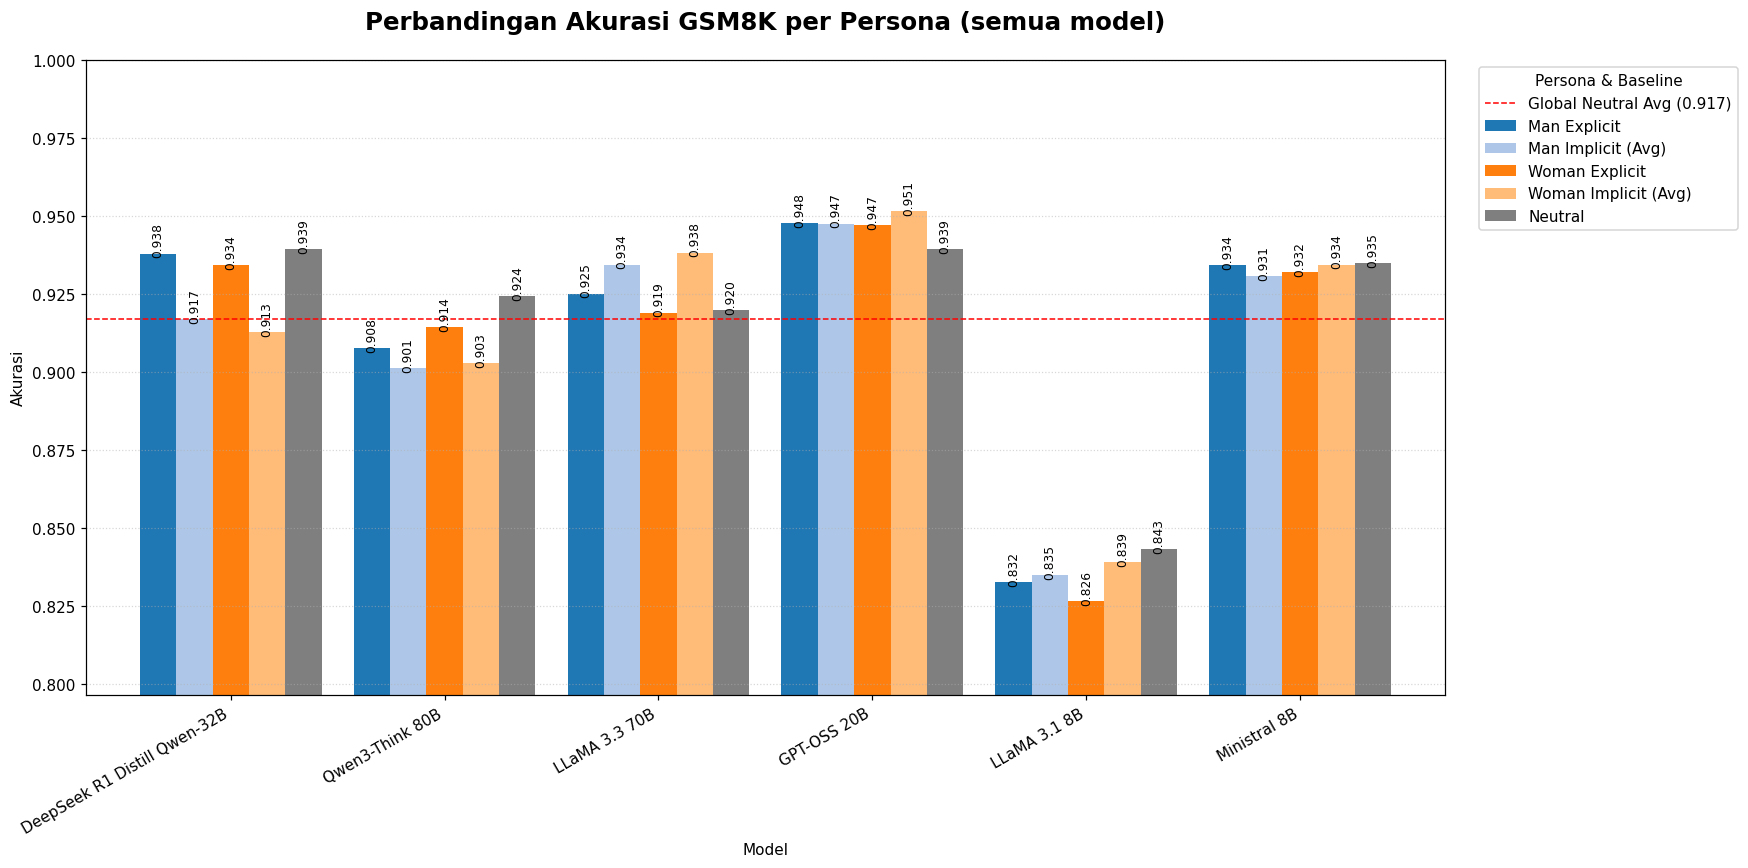

In [5]:
# ── 3.1 Grouped bar: akurasi per persona per model (gaya referensi) ──────────
column_order = ["Man Explicit", "Man Implicit (Avg)", "Woman Explicit",
                "Woman Implicit (Avg)", "Neutral"]
custom_colors = ["#1f77b4", "#aec7e8", "#ff7f0e", "#ffbb78", "#7f7f7f"]

ax = df_pivot[column_order].plot(kind="bar", figsize=(16, 8), width=0.85, color=custom_colors)

# skala y otomatis dengan lantai bawah agar beda antar-bar terlihat
vmin = float(df_pivot[column_order].min().min())
plt.ylim(max(0.0, vmin - 0.03), 1.0)

# garis baseline rata-rata neutral global
overall_neutral_avg = df_pivot["Neutral"].mean()
plt.axhline(overall_neutral_avg, color="red", ls="--", lw=1,
            label=f"Global Neutral Avg ({overall_neutral_avg:.3f})")

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.3f}",
                    (p.get_x() + p.get_width()/2., p.get_height()),
                    ha="center", va="center", xytext=(0, 9),
                    textcoords="offset points", fontsize=8, rotation=90)

plt.title("Perbandingan Akurasi GSM8K per Persona (semua model)", fontsize=16, pad=20, fontweight="bold")
plt.ylabel("Akurasi"); plt.xlabel("Model")
plt.legend(title="Persona & Baseline", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", ls=":", alpha=0.5)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_akurasi_grouped.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 4 — Analisis Gap Gender

Tiga visualisasi gap mengikuti referensi:
1. **Delta & Gender Gap** — Delta Man/Woman (Imp−Exp) dan Gender Gap (Man−Woman) per model.
2. **Deviation vs Neutral** — dampak menambahkan persona gender terhadap baseline neutral (disortir, dengan zona naik/turun).
3. **Dumbbell** — posisi akurasi Neutral vs rata-rata Man vs rata-rata Woman per model.

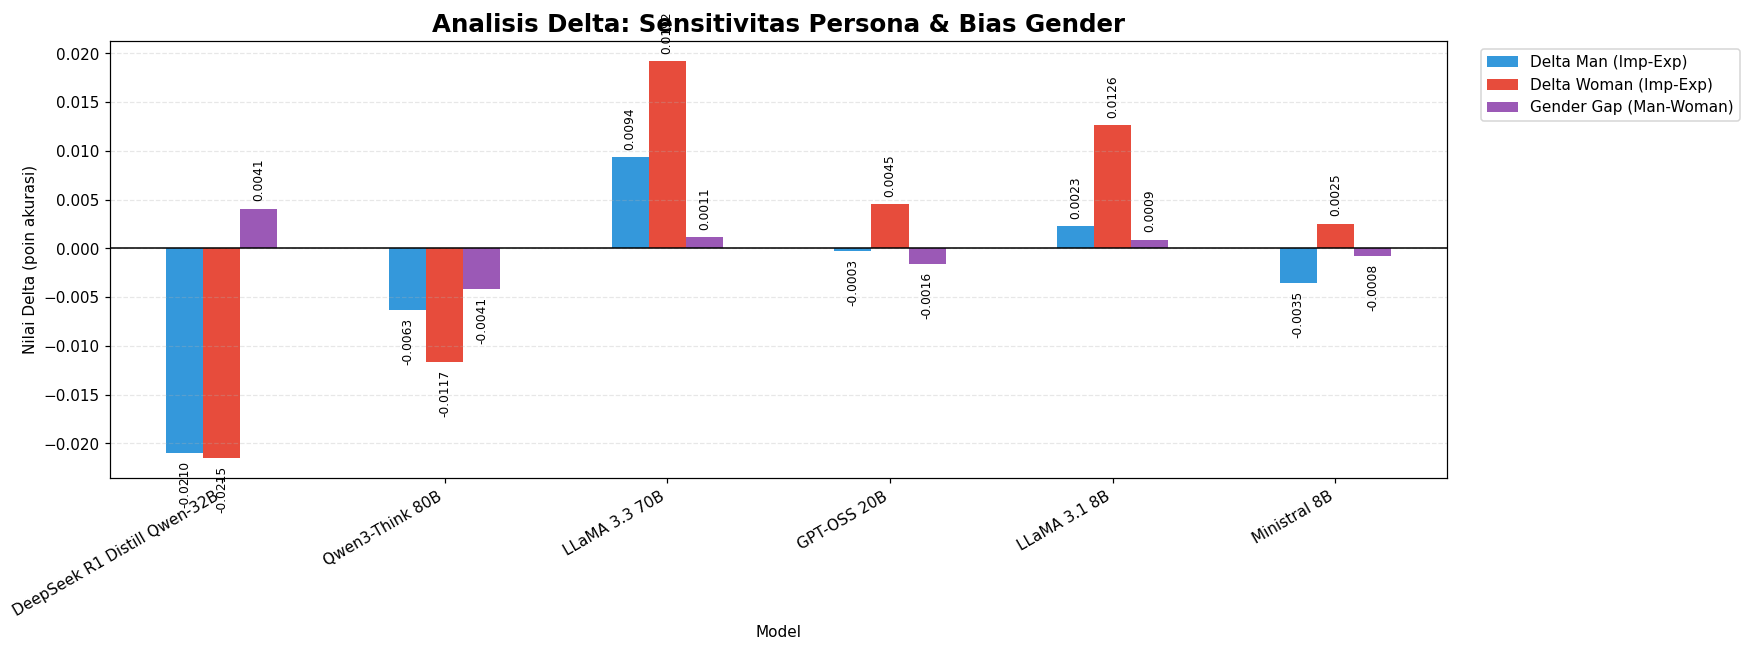

In [6]:
# ── 4.1 Bar: Delta (Imp-Exp) + Gender Gap ────────────────────────────────────
delta_cols = ["Delta Man (Imp-Exp)", "Delta Woman (Imp-Exp)", "Gender Gap (Man-Woman)"]
ax = df_pivot[delta_cols].plot(kind="bar", figsize=(16, 6), color=["#3498db", "#e74c3c", "#9b59b6"])
plt.axhline(0, color="black", lw=1)
for p in ax.patches:
    val = p.get_height()
    if pd.notna(val) and val != 0:
        va = "bottom" if val > 0 else "top"
        off = 5 if val > 0 else -5
        ax.annotate(f"{val:.4f}", (p.get_x() + p.get_width()/2., val),
                    ha="center", va=va, xytext=(0, off), textcoords="offset points",
                    fontsize=8, rotation=90)
plt.title("Analisis Delta: Sensitivitas Persona & Bias Gender", fontsize=16, fontweight="bold")
plt.ylabel("Nilai Delta (poin akurasi)")
plt.xticks(rotation=30, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", ls="--", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_delta_gendergap.png", dpi=150, bbox_inches="tight")
plt.show()

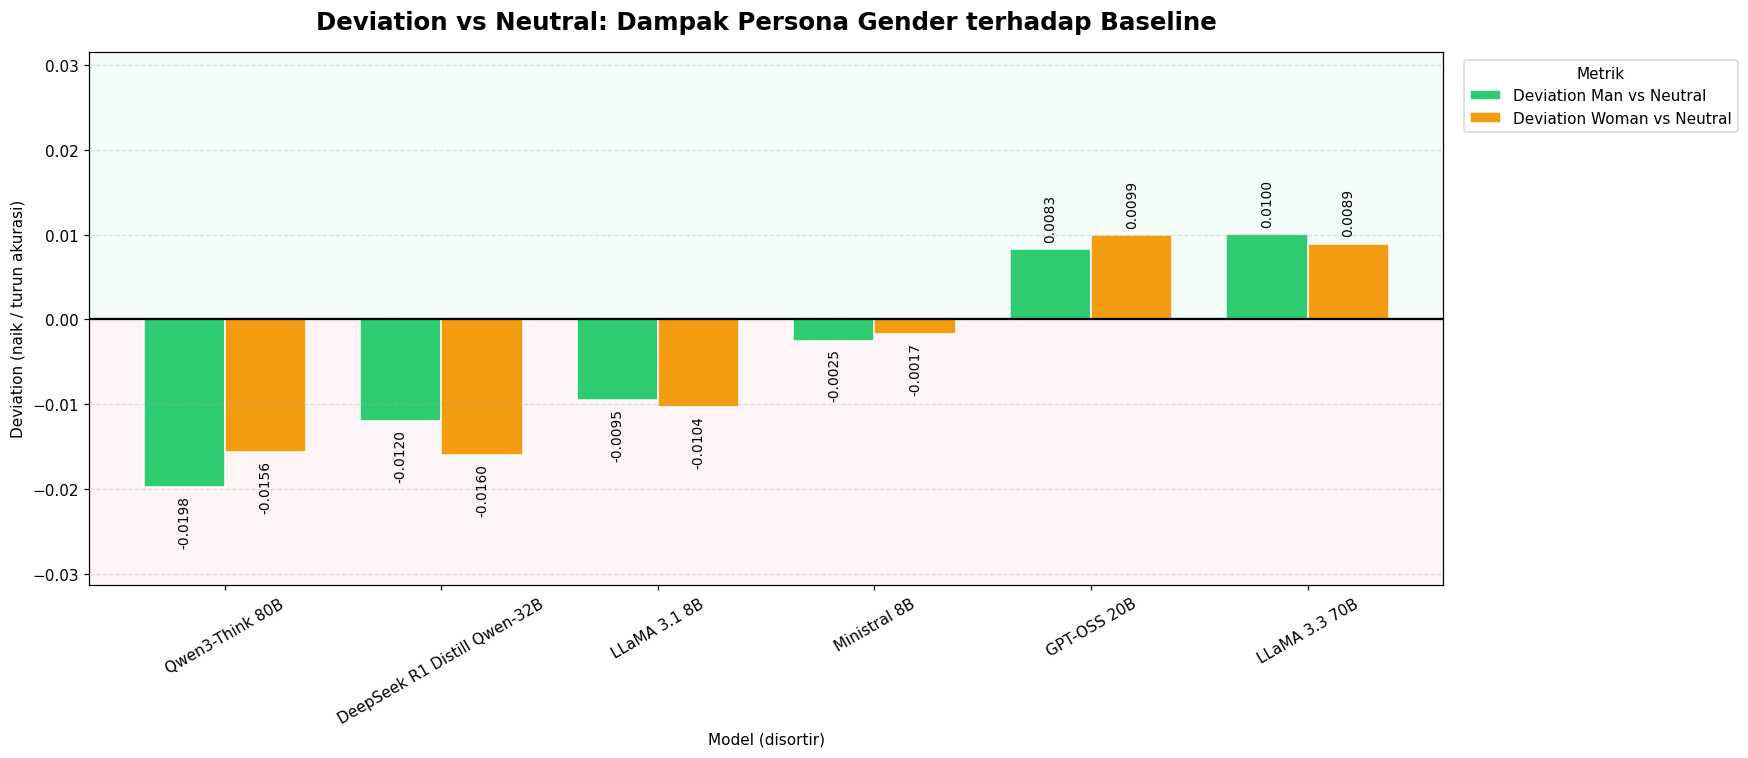

In [7]:
# ── 4.2 Bar: Deviation vs Neutral (disortir, dengan zona) ────────────────────
dev_cols = ["Deviation Man vs Neutral", "Deviation Woman vs Neutral"]
df_sorted_dev = df_pivot.assign(_avg=df_pivot[dev_cols].mean(axis=1)).sort_values("_avg")

fig, ax = plt.subplots(figsize=(16, 7))
df_sorted_dev[dev_cols].plot(kind="bar", ax=ax, color=["#2ecc71", "#f39c12"],
                             width=0.75, edgecolor="white")
ax.axhline(0, color="black", lw=1.5, zorder=3)
ymin, ymax = ax.get_ylim()
ax.axhspan(0, ymax + 0.05, facecolor="#2ecc71", alpha=0.05, zorder=0)
ax.axhspan(ymin - 0.05, 0, facecolor="#e74c3c", alpha=0.05, zorder=0)
for p in ax.patches:
    val = p.get_height()
    if pd.notna(val) and val != 0:
        va = "bottom" if val > 0 else "top"
        off = 5 if val > 0 else -5
        ax.annotate(f"{val:.4f}", (p.get_x() + p.get_width()/2., val),
                    ha="center", va=va, xytext=(0, off), textcoords="offset points",
                    fontsize=9, rotation=90)
ax.set_title("Deviation vs Neutral: Dampak Persona Gender terhadap Baseline",
             fontsize=16, fontweight="bold", pad=15)
ax.set_ylabel("Deviation (naik / turun akurasi)"); ax.set_xlabel("Model (disortir)")
ax.set_ylim(ymin - 0.01, ymax + 0.02)
ax.tick_params(axis="x", rotation=30)
ax.legend(title="Metrik", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", ls="--", alpha=0.4, zorder=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_deviation_neutral.png", dpi=150, bbox_inches="tight")
plt.show()

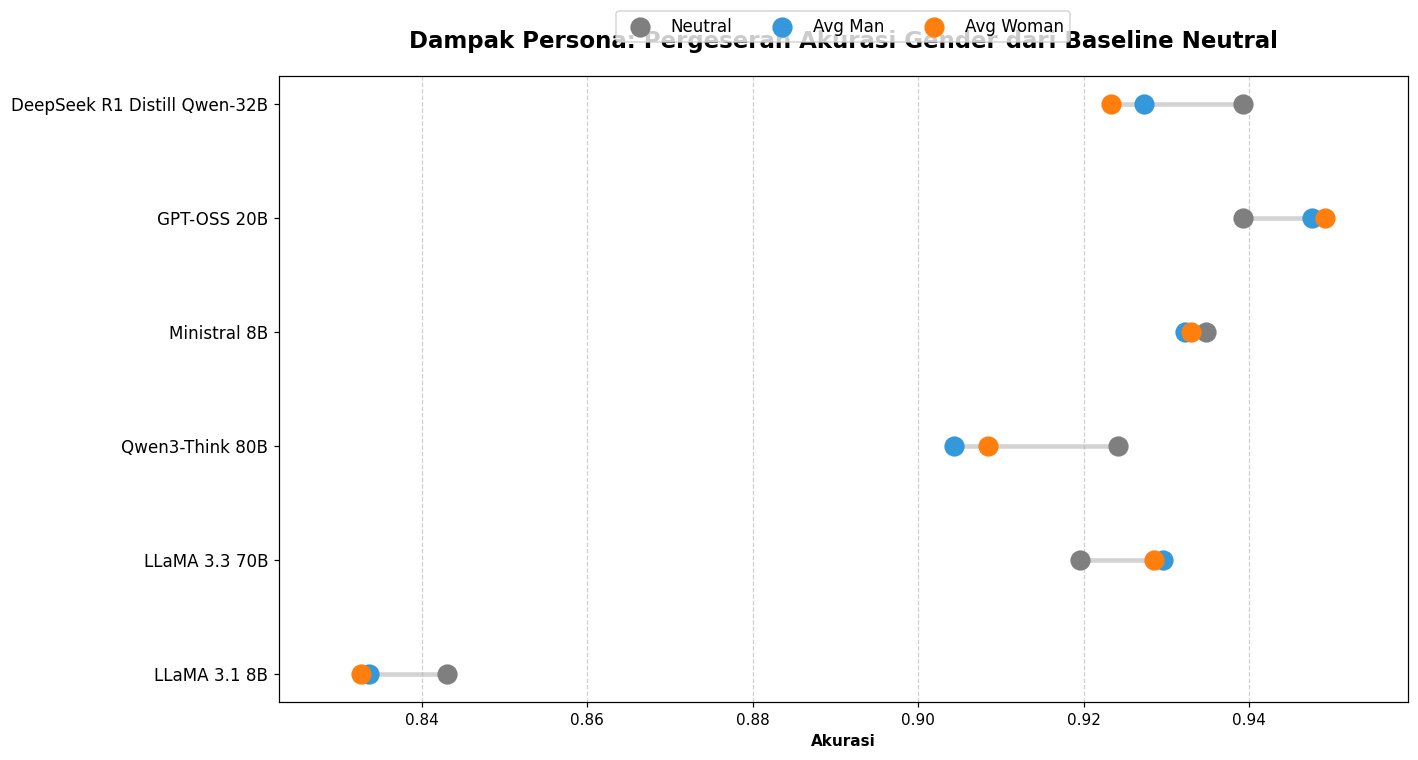

In [8]:
# ── 4.3 Dumbbell: Neutral vs Avg Man vs Avg Woman ────────────────────────────
df_sorted = df_pivot.sort_values("Neutral")
fig, ax = plt.subplots(figsize=(13, 7))
for i, m in enumerate(df_sorted.index):
    nv = df_sorted.loc[m, "Neutral"]; mv = df_sorted.loc[m, "Avg Man"]; wv = df_sorted.loc[m, "Avg Woman"]
    ax.plot([min(nv, mv, wv), max(nv, mv, wv)], [i, i], color="lightgray", lw=3, zorder=1)
    ax.scatter(nv, i, color="#7f7f7f", s=150, zorder=3, label="Neutral" if i == 0 else "")
    ax.scatter(mv, i, color="#3498db", s=150, zorder=3, label="Avg Man" if i == 0 else "")
    ax.scatter(wv, i, color="#ff7f0e", s=150, zorder=3, label="Avg Woman" if i == 0 else "")
ax.set_yticks(range(len(df_sorted))); ax.set_yticklabels(df_sorted.index, fontsize=11)
ax.set_xlabel("Akurasi", fontweight="bold")
ax.set_title("Dampak Persona: Pergeseran Akurasi Gender dari Baseline Neutral",
             fontsize=15, pad=18, fontweight="bold")
lo = df_sorted[["Neutral","Avg Man","Avg Woman"]].min().min() - 0.01
hi = df_sorted[["Neutral","Avg Man","Avg Woman"]].max().max() + 0.01
ax.set_xlim(lo, hi)
ax.xaxis.grid(True, ls="--", alpha=0.6); ax.yaxis.grid(False)
ax.legend(bbox_to_anchor=(0.5, 1.04), loc="lower center", ncol=3, fontsize=11)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_dumbbell.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 5 — Token per Persona (Deskriptif, semua model)

CSV hanya menyimpan **rata-rata** token per persona (bukan distribusi per soal), sehingga
uji signifikansi token (Mann-Whitney/Shapiro) tidak dapat dijalankan — lihat Bagian 7.
Perbedaan `prompt_tokens` explicit vs implicit **didorong panjang narasi persona implicit**
(confound), bukan semata gaya reasoning.

=== Rata-rata TOTAL token per persona per model ===
                              Man Explicit  Man Implicit (Avg)  Woman Explicit  Woman Implicit (Avg)  Neutral
Model                                                                                                        
DeepSeek R1 Distill Qwen-32B         509.5              1085.2           520.8                1043.2    511.8
Qwen3-Think 80B                      996.7              1697.0           987.2                1587.8   1024.7
LLaMA 3.3 70B                        288.5               779.8           285.4                 641.2    279.4
GPT-OSS 20B                          447.3              1213.1           441.2                1206.4    486.4
LLaMA 3.1 8B                         282.4               679.5           288.5                 610.6    275.2
Ministral 8B                         380.0              1217.7           382.8                 960.9      NaN


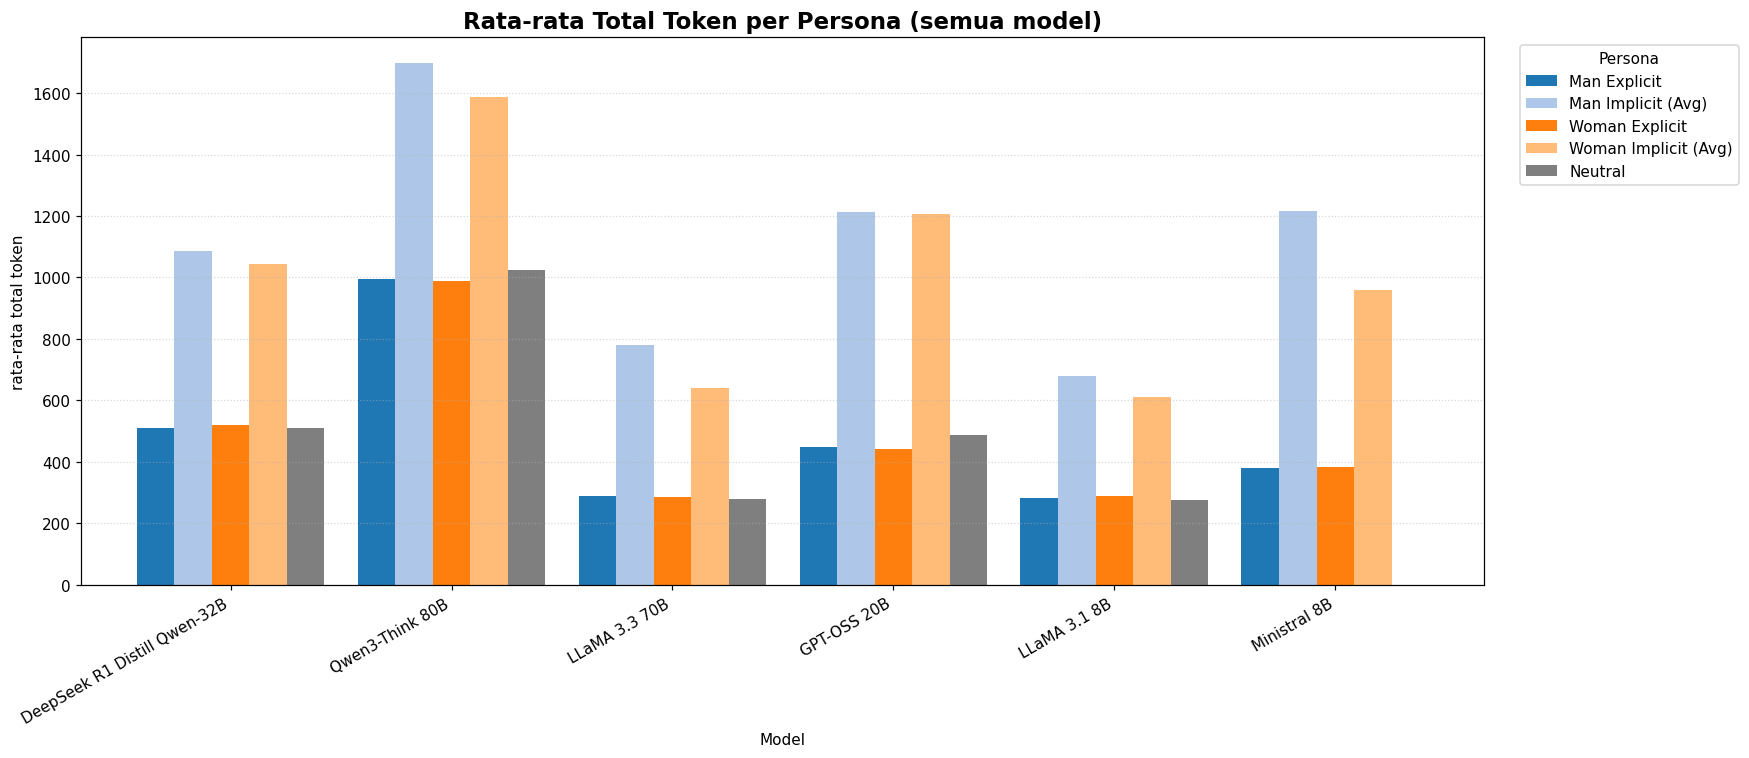

In [9]:
# ── 5.1 Pivot rata-rata total token per persona per model + grouped bar ──────
def tok_of(sub, persona, col="avg_total_tokens"):
    r = sub[sub["persona_folder"] == persona]
    return r[col].iloc[0] if len(r) else np.nan
def tok_avg(sub, personas, col="avg_total_tokens"):
    return np.nanmean([tok_of(sub, p, col) for p in personas])

rows = []
for m in MODELS:
    s = data[data["model_label"] == m]
    rows.append({
        "Model": m,
        "Man Explicit":        tok_of(s, "man_explicit_1"),
        "Man Implicit (Avg)":  tok_avg(s, ["man_implicit_1","man_implicit_2","man_implicit_3"]),
        "Woman Explicit":      tok_of(s, "woman_explicit_1"),
        "Woman Implicit (Avg)":tok_avg(s, ["woman_implicit_1","woman_implicit_2","woman_implicit_3"]),
        "Neutral":             tok_of(s, "neutral"),
    })
tok_pivot = pd.DataFrame(rows).set_index("Model")
print("=== Rata-rata TOTAL token per persona per model ===")
print(tok_pivot.round(1).to_string())
tok_pivot.round(2).to_csv(OUTPUT_DIR / "pivot_token_total.csv")

ax = tok_pivot[column_order].plot(kind="bar", figsize=(16, 7), width=0.85, color=custom_colors)
plt.title("Rata-rata Total Token per Persona (semua model)", fontsize=15, fontweight="bold")
plt.ylabel("rata-rata total token"); plt.xlabel("Model")
plt.legend(title="Persona", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", ls=":", alpha=0.5)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_token_grouped.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 6 — Uji Signifikansi Akurasi per Model (berbasis hitungan)

Untuk tiap model diuji dari **jumlah benar/salah** (valid untuk data agregat):
- **Chi-square omnibus** (9 persona) + Cramér's V — apakah akurasi bergantung persona.
- **Two-proportion z-test** Explicit vs Implicit dan Man vs Woman (hitungan digabung),
  + effect size **Cohen's h**. Koreksi **Holm** diterapkan pada kumpulan p-value.

In [10]:
# ── 6.1 Fungsi uji + rangkuman lintas model ──────────────────────────────────
def two_prop_z(x1, n1, x2, n2):
    p1, p2 = x1/n1, x2/n2
    pp = (x1 + x2) / (n1 + n2)
    se = np.sqrt(pp*(1-pp)*(1/n1 + 1/n2))
    z = (p1 - p2)/se if se > 0 else 0.0
    return z, 2*(1-norm.cdf(abs(z))), p1, p2
def cohens_h(p1, p2):
    return 2*np.arcsin(np.sqrt(p1)) - 2*np.arcsin(np.sqrt(p2))
def interp_h(h):
    a = abs(h)
    return "besar" if a>=0.8 else "sedang" if a>=0.5 else "kecil" if a>=0.2 else "diabaikan"
def holm(pvals, alpha=0.05):
    pv = np.asarray(pvals, float); m = len(pv); order = np.argsort(pv)
    adj = np.empty(m); run = 0.0
    for rank, idx in enumerate(order):
        run = max(run, (m-rank)*pv[idx]); adj[idx] = min(run, 1.0)
    return adj, adj < alpha

def sum_counts(s, personas):
    r = s[s["persona_folder"].isin(personas)]
    return int(r["correct"].sum()), int(r["total"].sum())

MAN_EXP = ["man_explicit_1"]; WOMAN_EXP = ["woman_explicit_1"]
MAN_IMP = ["man_implicit_1","man_implicit_2","man_implicit_3"]
WOMAN_IMP = ["woman_implicit_1","woman_implicit_2","woman_implicit_3"]
EXPLICIT = MAN_EXP + WOMAN_EXP
IMPLICIT = MAN_IMP + WOMAN_IMP
MAN_ALL = MAN_EXP + MAN_IMP; WOMAN_ALL = WOMAN_EXP + WOMAN_IMP

rows = []
for m in MODELS:
    s = data[data["model_label"] == m]
    # chi-square omnibus 9 persona
    ct = s.set_index("persona_folder").reindex(PERSONA_ORDER)[["correct","wrong"]].dropna()
    chi2, p_chi, dof, _ = chi2_contingency(ct.values)
    V = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape)-1)))
    # explicit vs implicit
    xe, ne = sum_counts(s, EXPLICIT); xi, ni = sum_counts(s, IMPLICIT)
    z_ei, p_ei, pe, pi = two_prop_z(xe, ne, xi, ni); h_ei = cohens_h(pe, pi)
    # man vs woman
    xm, nm = sum_counts(s, MAN_ALL); xw, nw = sum_counts(s, WOMAN_ALL)
    z_mw, p_mw, pm, pw = two_prop_z(xm, nm, xw, nw); h_mw = cohens_h(pm, pw)
    rows.append({
        "Model": m,
        "chi2": round(chi2,2), "p_chi": p_chi, "CramerV": round(V,4),
        "ExpVsImp_acc": f"{pe*100:.2f}/{pi*100:.2f}", "p_ExpImp": p_ei,
        "h_ExpImp": round(h_ei,3), "eff_ExpImp": interp_h(h_ei),
        "ManVsWoman_acc": f"{pm*100:.2f}/{pw*100:.2f}", "p_ManWoman": p_mw,
        "h_ManWoman": round(h_mw,3), "eff_ManWoman": interp_h(h_mw),
    })
sig = pd.DataFrame(rows)
# Koreksi Holm per keluarga uji
for col, out in [("p_chi","chi_sig"), ("p_ExpImp","ExpImp_sig"), ("p_ManWoman","ManWoman_sig")]:
    _, rej = holm(sig[col].values); sig[out] = rej
for c in ["p_chi","p_ExpImp","p_ManWoman"]:
    sig[c] = sig[c].map(lambda v: f"{v:.4g}")
print("=== Ringkasan Uji Signifikansi Akurasi Lintas Model ===\n")
print(sig.to_string(index=False))
sig.to_csv(OUTPUT_DIR / "signifikansi_lintas_model.csv", index=False)

=== Ringkasan Uji Signifikansi Akurasi Lintas Model ===

                       Model  chi2     p_chi  CramerV ExpVsImp_acc p_ExpImp  h_ExpImp eff_ExpImp ManVsWoman_acc p_ManWoman  h_ManWoman eff_ManWoman  chi_sig  ExpImp_sig  ManWoman_sig
DeepSeek R1 Distill Qwen-32B 26.82 0.0007599   0.0475  93.59/91.47 0.000497     0.081  diabaikan    92.21/91.79     0.4281       0.015    diabaikan     True        True         False
             Qwen3-Think 80B  8.95    0.3467   0.0275  91.09/90.19    0.174     0.031  diabaikan    90.28/90.56     0.6243      -0.010    diabaikan    False       False         False
               LLaMA 3.3 70B 11.21      0.19   0.0307  92.19/93.62  0.01129    -0.056  diabaikan    93.20/93.33     0.7857      -0.005    diabaikan    False       False         False
                 GPT-OSS 20B  5.20    0.7363   0.0209  94.73/94.95   0.6643    -0.010  diabaikan    94.75/95.03     0.5072      -0.013    diabaikan    False       False         False
                LLaMA 3.1 8B

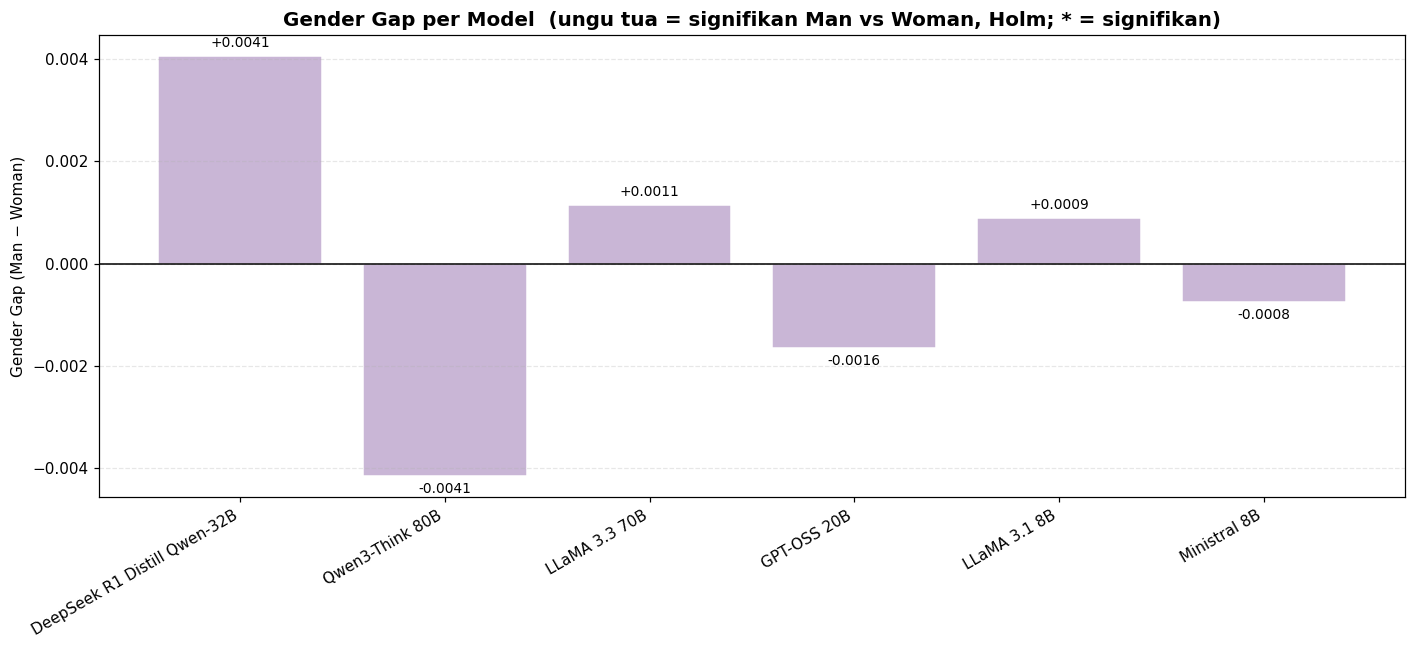

In [11]:
# ── 6.2 Grafik Gender Gap + tanda signifikansi (Man vs Woman) ────────────────
gap = df_pivot["Gender Gap (Man-Woman)"].reindex(MODELS)
sig_map = dict(zip(sig["Model"], sig["ManWoman_sig"]))
colors = ["#9b59b6" if sig_map.get(m) else "#c9b6d6" for m in MODELS]
fig, ax = plt.subplots(figsize=(13, 6))
bars = ax.bar(range(len(MODELS)), gap.values, color=colors, edgecolor="white")
ax.axhline(0, color="black", lw=1)
for i, (m, v) in enumerate(zip(MODELS, gap.values)):
    star = " *" if sig_map.get(m) else ""
    va = "bottom" if v >= 0 else "top"; off = 4 if v >= 0 else -4
    ax.annotate(f"{v:+.4f}{star}", (i, v), ha="center", va=va,
                xytext=(0, off), textcoords="offset points", fontsize=9)
ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS, rotation=30, ha="right")
ax.set_ylabel("Gender Gap (Man − Woman)")
ax.set_title("Gender Gap per Model  (ungu tua = signifikan Man vs Woman, Holm; * = signifikan)",
             fontsize=13, fontweight="bold")
ax.grid(axis="y", ls="--", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_gender_gap_sig.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 7 — Keterbatasan & Ringkasan

**Uji yang TIDAK dijalankan** (butuh data per-soal yang tidak ada pada rekap agregat):
McNemar & Cochran's Q (berpasangan), Mann-Whitney U & Shapiro-Wilk (distribusi token),
serta regresi logistik/mixed-effects. Untuk melengkapinya, muat data mentah per-soal dari
`result/GMS8K/Gender_Persona/<model>/<persona>/gsm8k_XXXXX.json`.

**Metode yang dipakai (siap tulis Bab VI):** akurasi deskriptif per persona; pivot
model × persona; metrik gap (Delta Imp−Exp, Gender Gap Man−Woman, Deviation vs Neutral);
chi-square + Cramér's V; two-proportion z-test + Cohen's h + koreksi Holm; token deskriptif.

Rujukan: Pearson (1900); Cramér (1946); Cohen (1988); Holm (1979).

In [12]:
# ── 7.1 Daftar output ────────────────────────────────────────────────────────
print("Output tersimpan di:", OUTPUT_DIR.resolve(), "\n")
for f in sorted(OUTPUT_DIR.glob("*")):
    print("  -", f.name)
print(f"\nSelesai. {len(MODELS)} model dianalisis: {', '.join(MODELS)}")

Output tersimpan di: D:\TugasAkhir\src\notebook\GSM8K\outputs_notebook1 

  - akurasi_deskriptif.csv
  - fig_akurasi_grouped.png
  - fig_akurasi_persona.png
  - fig_delta_gendergap.png
  - fig_deviation_neutral.png
  - fig_dumbbell.png
  - fig_gender_gap_sig.png
  - fig_token_grouped.png
  - fig_token_rata2.png
  - fisher_akurasi.csv
  - narasi_bab6.txt
  - pivot_akurasi_gap.csv
  - pivot_token_total.csv
  - ringkasan_lintas_model.csv
  - signifikansi_lintas_model.csv
  - token_explicit_vs_implicit.csv
  - token_rata2.csv
  - ztest_akurasi.csv

Selesai. 6 model dianalisis: DeepSeek R1 Distill Qwen-32B, Qwen3-Think 80B, LLaMA 3.3 70B, GPT-OSS 20B, LLaMA 3.1 8B, Ministral 8B
